# Health Insurance Claim Cost Classification

**Objective:** classify an insurance claim as `Low-cost` or `High-cost` using the available customer and health features.

This notebook follows a practical-style implementation: preprocessing, encoding, scaling, model definition, training, prediction, and evaluation are shown as separate steps. **No `Pipeline` is used.**

## 1. Import libraries and load the dataset

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

RANDOM_STATE = 42

df = pd.read_csv("health_insurance.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (15000, 13)


,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title,claim
0,60.0,male,64,24.3,NoDisease,1,0,NewYork,72,0,0,Actor,13112.6
1,49.0,female,75,22.6,NoDisease,1,0,Boston,78,1,1,Engineer,9567.0
2,32.0,female,64,17.8,Epilepsy,2,1,Phildelphia,88,1,1,Academician,32734.2
3,61.0,female,53,36.4,NoDisease,1,1,Pittsburg,72,1,0,Chef,48517.6
4,19.0,female,50,20.6,NoDisease,0,0,Buffalo,82,1,0,HomeMakers,1731.7


In [ ]:
print("Column names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()
print("\nMissing values:")
display(df.isna().sum().to_frame("Missing Values"))
print("Duplicate rows:", df.duplicated().sum())

Column names:
['age', 'sex', 'weight', 'bmi', 'hereditary_diseases', 'no_of_dependents', 'smoker', 'city', 'bloodpressure', 'diabetes', 'regular_ex', 'job_title', 'claim']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  14604 non-null  float64
 1   sex                  15000 non-null  object 
 2   weight               15000 non-null  int64  
 3   bmi                  14044 non-null  float64
 4   hereditary_diseases  15000 non-null  object 
 5   no_of_dependents     15000 non-null  int64  
 6   smoker               15000 non-null  int64  
 7   city                 15000 non-null  object 
 8   bloodpressure        15000 non-null  int64  
 9   diabetes             15000 non-null  int64  
 10  regular_ex           15000 non-null  int64  
 11  job_title            15000 non-

,Missing Values
age,396
sex,0
weight,0
bmi,956
hereditary_diseases,0
no_of_dependents,0
smoker,0
city,0
bloodpressure,0
diabetes,0


Duplicate rows: 1096


In [ ]:
# Remove exact duplicate rows before preparing the target.
df = df.drop_duplicates().reset_index(drop=True)

# Convert the continuous claim amount into two classes using the dataset median.
claim_threshold = df["claim"].median()
df["claim_class"] = np.where(df["claim"] >= claim_threshold, "High-cost", "Low-cost")

print(f"Median claim threshold: {claim_threshold:,.2f}")
print("Class distribution:")
display(df["claim_class"].value_counts().to_frame("Count"))

Median claim threshold: 9,567.00
Class distribution:


,Count
claim_class,
High-cost,6956
Low-cost,6948


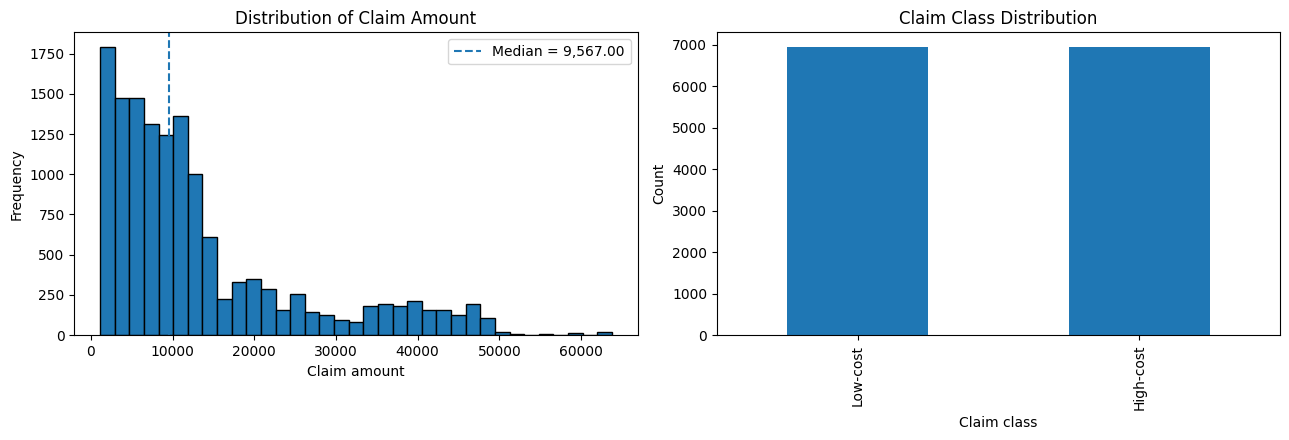

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(df["claim"], bins=35, edgecolor="black")
axes[0].axvline(claim_threshold, linestyle="--", label=f"Median = {claim_threshold:,.2f}")
axes[0].set_title("Distribution of Claim Amount")
axes[0].set_xlabel("Claim amount")
axes[0].set_ylabel("Frequency")
axes[0].legend()

df["claim_class"].value_counts().reindex(["Low-cost", "High-cost"]).plot(kind="bar", ax=axes[1])
axes[1].set_title("Claim Class Distribution")
axes[1].set_xlabel("Claim class")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

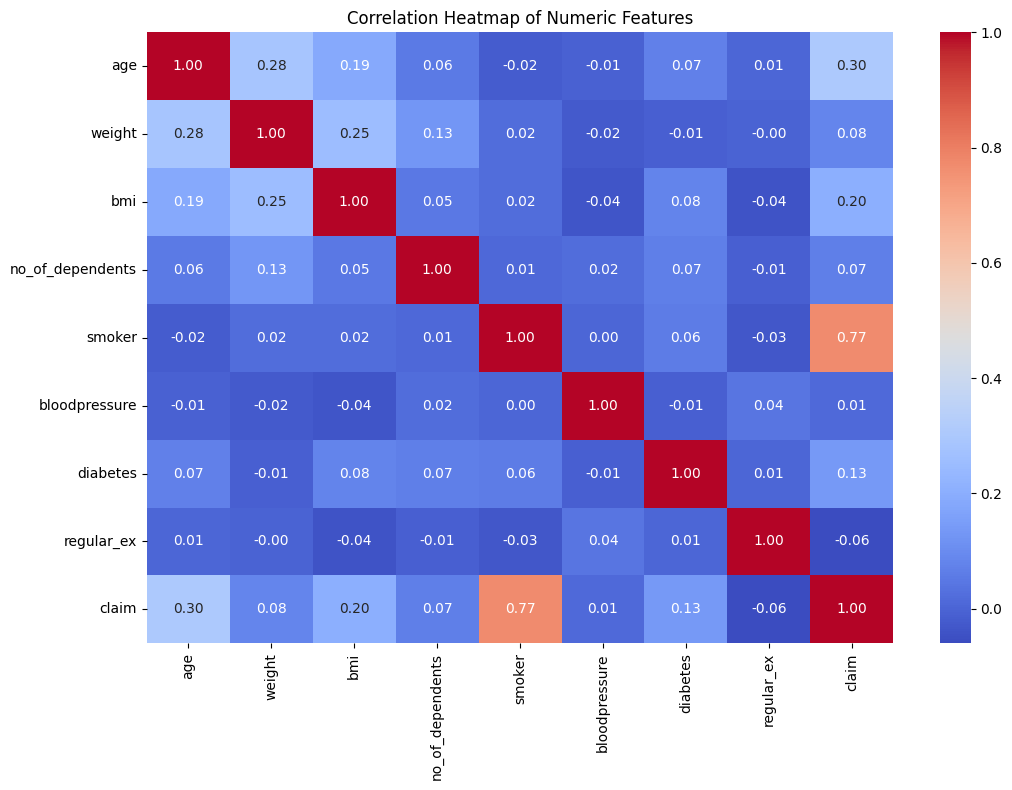

In [ ]:
# Correlation heatmap for numeric columns.
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(11, 8))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

### Prepare the input features and target

The original `claim` amount is excluded from the inputs because it is used to create the class label. The class represents claims below or at/above the dataset median; it does **not** predict an exact claim amount.

In [ ]:
X = df.drop(columns=["claim", "claim_class"]).copy()
y = df["claim_class"].copy()

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Input shape: (13904, 12)
Target shape: (13904,)
Numeric features: ['age', 'weight', 'bmi', 'no_of_dependents', 'smoker', 'bloodpressure', 'diabetes', 'regular_ex']
Categorical features: ['sex', 'hereditary_diseases', 'city', 'job_title']


## 2. Define a practical-style preprocessing function

This helper performs the steps manually, rather than using a `Pipeline`:
1. Fill missing numeric values using training-set medians.
2. Fill missing categorical values using training-set modes.
3. Convert categorical columns to numeric columns using one-hot encoding.
4. Align test columns with training columns.
5. Optionally scale the features using a separately fitted `StandardScaler`.

The imputation values, encodings, and scaler are learned from the training data only.

In [ ]:
def prepare_data(X_train_raw, X_test_raw, scale=True):
    X_train = X_train_raw.copy()
    X_test = X_test_raw.copy()

    # Fill numeric missing values using training-set medians.
    for col in X_train.select_dtypes(include=np.number).columns:
        median_value = X_train[col].median()
        X_train[col] = X_train[col].fillna(median_value)
        X_test[col] = X_test[col].fillna(median_value)

    # Fill categorical missing values using training-set modes.
    for col in X_train.select_dtypes(exclude=np.number).columns:
        modes = X_train[col].mode(dropna=True)
        fill_value = modes.iloc[0] if len(modes) else "Unknown"
        X_train[col] = X_train[col].fillna(fill_value)
        X_test[col] = X_test[col].fillna(fill_value)

    # One-hot encode categorical features and align test columns to train columns.
    X_train = pd.get_dummies(X_train, drop_first=False, dtype=int)
    X_test = pd.get_dummies(X_test, drop_first=False, dtype=int)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    scaler = None
    if scale:
        scaler = StandardScaler()
        X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
        X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

    return X_train, X_test, scaler

## 3. Compare train-test ratios and finalize one

Logistic Regression is used as the same reference algorithm for each split ratio. Each split is stratified and uses the same random state. The ratio with the highest F1-score is selected (accuracy breaks ties). This comparison is for this project dataset; a selected ratio is not universally best for every dataset.

In [ ]:
split_ratios = {"80:20": 0.20, "70:30": 0.30, "75:25": 0.25, "60:40": 0.40}
split_results = []

for split_name, test_size in split_ratios.items():
    X_train_split, X_test_split, y_train_split, y_test_split = train_test_split(
        X, y, test_size=test_size, random_state=RANDOM_STATE, stratify=y
    )
    X_train_p, X_test_p, _ = prepare_data(X_train_split, X_test_split, scale=True)
    reference_model = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
    reference_model.fit(X_train_p, y_train_split)
    predictions = reference_model.predict(X_test_p)
    split_results.append({
        "Train-Test Split": split_name,
        "Accuracy": accuracy_score(y_test_split, predictions),
        "Precision": precision_score(y_test_split, predictions, pos_label="High-cost", zero_division=0),
        "Recall": recall_score(y_test_split, predictions, pos_label="High-cost", zero_division=0),
        "F1-score": f1_score(y_test_split, predictions, pos_label="High-cost", zero_division=0)
    })

split_results_df = pd.DataFrame(split_results)
display(split_results_df.style.format({"Accuracy":"{:.4f}", "Precision":"{:.4f}", "Recall":"{:.4f}", "F1-score":"{:.4f}"}))

,Train-Test Split,Accuracy,Precision,Recall,F1-score
0,80:20,0.8828,0.8884,0.8756,0.8820
1,70:30,0.8833,0.8964,0.8668,0.8814
2,75:25,0.8815,0.8896,0.8712,0.8803
3,60:40,0.8840,0.8953,0.8699,0.8824


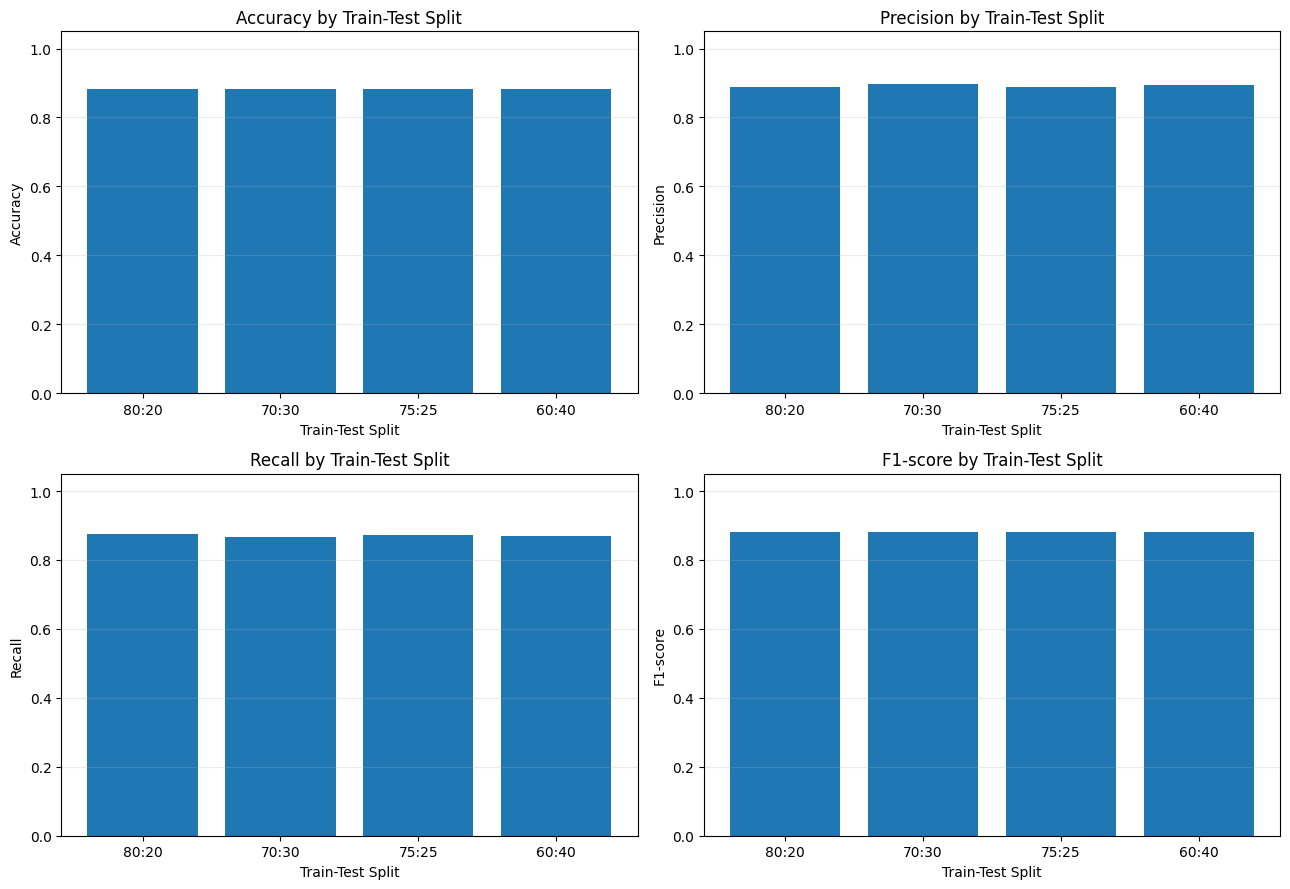

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, metric in zip(axes.flat, ["Accuracy", "Precision", "Recall", "F1-score"]):
    ax.bar(split_results_df["Train-Test Split"], split_results_df[metric])
    ax.set_title(f"{metric} by Train-Test Split")
    ax.set_xlabel("Train-Test Split")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
split_ranking = split_results_df.sort_values(by=["F1-score", "Accuracy"], ascending=False).reset_index(drop=True)
selected_split = split_ranking.loc[0, "Train-Test Split"]
selected_test_size = split_ratios[selected_split]
print("Selected split:", selected_split)
print("Selection rule: highest F1-score, with accuracy used to break ties.")
display(split_ranking)

Selected split: 60:40
Selection rule: highest F1-score, with accuracy used to break ties.


,Train-Test Split,Accuracy,Precision,Recall,F1-score
0,60:40,0.884035,0.895340,0.869925,0.882449
1,80:20,0.882776,0.888403,0.875629,0.881970
2,70:30,0.883269,0.896432,0.866794,0.881364
3,75:25,0.881473,0.889607,0.871190,0.880302


## 4. Fix the selected split and compare all four algorithms

From this point onward, only the selected split is used. Each algorithm is trained and evaluated on the same training and test rows. Scaling is applied to Logistic Regression, KNN, and Linear SVM; the Decision Tree is evaluated without scaling, as tree models do not require feature scaling.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=selected_test_size, random_state=RANDOM_STATE, stratify=y
)

X_train_scaled, X_test_scaled, scaler_for_scaled_models = prepare_data(X_train, X_test, scale=True)
X_train_unscaled, X_test_unscaled, _ = prepare_data(X_train, X_test, scale=False)

print(f"Finalized split: {selected_split}")
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))
print("Encoded training feature shape:", X_train_scaled.shape)

Finalized split: 60:40
Training rows: 8342 | Testing rows: 5562
Encoded training feature shape: (8342, 146)


In [ ]:
# Algorithm 1: Logistic Regression
logistic_model = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
logistic_model.fit(X_train_scaled, y_train)
logistic_predictions = logistic_model.predict(X_test_scaled)

logistic_scores = {
    "Algorithm": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, logistic_predictions),
    "Precision": precision_score(y_test, logistic_predictions, pos_label="High-cost", zero_division=0),
    "Recall": recall_score(y_test, logistic_predictions, pos_label="High-cost", zero_division=0),
    "F1-score": f1_score(y_test, logistic_predictions, pos_label="High-cost", zero_division=0)
}
print("Logistic Regression")
for metric, value in logistic_scores.items():
    if metric != "Algorithm": print(f"{metric}: {value:.4f}")

Logistic Regression
Accuracy: 0.8840
Precision: 0.8953
Recall: 0.8699
F1-score: 0.8824


In [ ]:
# Algorithm 2: K-Nearest Neighbors (KNN)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_predictions = knn_model.predict(X_test_scaled)

knn_scores = {
    "Algorithm": "KNN Classifier",
    "Accuracy": accuracy_score(y_test, knn_predictions),
    "Precision": precision_score(y_test, knn_predictions, pos_label="High-cost", zero_division=0),
    "Recall": recall_score(y_test, knn_predictions, pos_label="High-cost", zero_division=0),
    "F1-score": f1_score(y_test, knn_predictions, pos_label="High-cost", zero_division=0)
}
print("KNN Classifier")
for metric, value in knn_scores.items():
    if metric != "Algorithm": print(f"{metric}: {value:.4f}")

KNN Classifier
Accuracy: 0.6411
Precision: 0.6627
Recall: 0.5760
F1-score: 0.6163


In [ ]:
# Algorithm 3: Decision Tree Classifier
tree_model = DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE)
tree_model.fit(X_train_unscaled, y_train)
tree_predictions = tree_model.predict(X_test_unscaled)

tree_scores = {
    "Algorithm": "Decision Tree Classifier",
    "Accuracy": accuracy_score(y_test, tree_predictions),
    "Precision": precision_score(y_test, tree_predictions, pos_label="High-cost", zero_division=0),
    "Recall": recall_score(y_test, tree_predictions, pos_label="High-cost", zero_division=0),
    "F1-score": f1_score(y_test, tree_predictions, pos_label="High-cost", zero_division=0)
}
print("Decision Tree Classifier")
for metric, value in tree_scores.items():
    if metric != "Algorithm": print(f"{metric}: {value:.4f}")

Decision Tree Classifier
Accuracy: 0.9371
Precision: 0.9739
Recall: 0.8983
F1-score: 0.9346


In [ ]:
# Algorithm 4: Linear Support Vector Machine (SVM)
svm_model = LinearSVC(random_state=RANDOM_STATE, max_iter=10000)
svm_model.fit(X_train_scaled, y_train)
svm_predictions = svm_model.predict(X_test_scaled)

svm_scores = {
    "Algorithm": "Linear SVM",
    "Accuracy": accuracy_score(y_test, svm_predictions),
    "Precision": precision_score(y_test, svm_predictions, pos_label="High-cost", zero_division=0),
    "Recall": recall_score(y_test, svm_predictions, pos_label="High-cost", zero_division=0),
    "F1-score": f1_score(y_test, svm_predictions, pos_label="High-cost", zero_division=0)
}
print("Linear SVM")
for metric, value in svm_scores.items():
    if metric != "Algorithm": print(f"{metric}: {value:.4f}")

Linear SVM
Accuracy: 0.8821
Precision: 0.8926
Recall: 0.8688
F1-score: 0.8806


In [ ]:
algorithm_results = pd.DataFrame([logistic_scores, knn_scores, tree_scores, svm_scores])
algorithm_results = algorithm_results.sort_values("F1-score", ascending=False).reset_index(drop=True)
display(algorithm_results.style.format({"Accuracy":"{:.4f}", "Precision":"{:.4f}", "Recall":"{:.4f}", "F1-score":"{:.4f}"}))

,Algorithm,Accuracy,Precision,Recall,F1-score
0,Decision Tree Classifier,0.9371,0.9739,0.8983,0.9346
1,Logistic Regression,0.8840,0.8953,0.8699,0.8824
2,Linear SVM,0.8821,0.8926,0.8688,0.8806
3,KNN Classifier,0.6411,0.6627,0.5760,0.6163


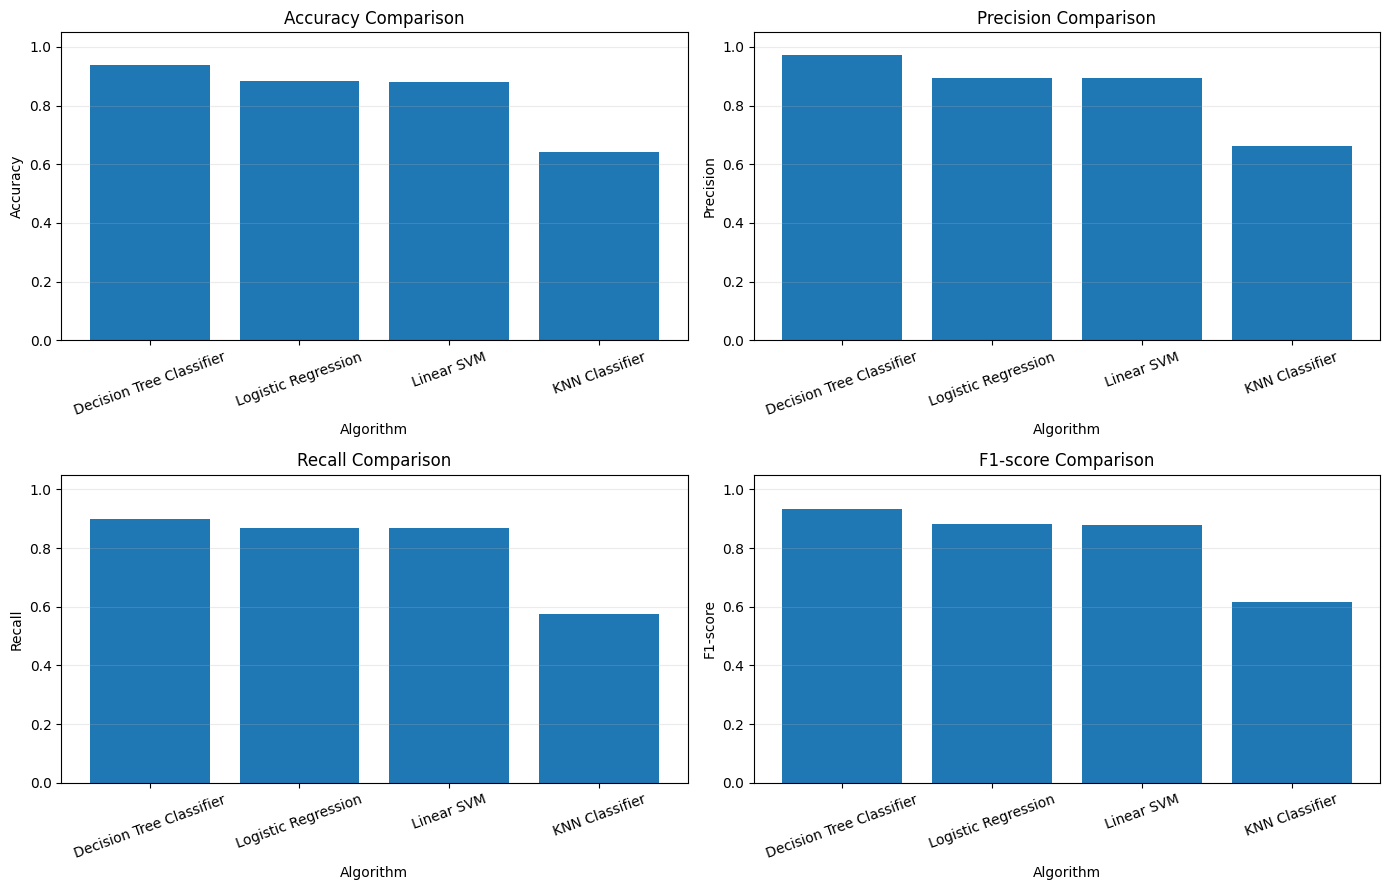

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, metric in zip(axes.flat, ["Accuracy", "Precision", "Recall", "F1-score"]):
    plot_data = algorithm_results.sort_values(metric, ascending=False)
    ax.bar(plot_data["Algorithm"], plot_data[metric])
    ax.set_title(f"{metric} Comparison")
    ax.set_xlabel("Algorithm")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
best_algorithm_name = algorithm_results.iloc[0]["Algorithm"]
print("Best algorithm based on F1-score:", best_algorithm_name)
print(f"F1-score: {algorithm_results.iloc[0]['F1-score']:.4f}")
print("The other metrics are used as supporting measures.")

Best algorithm based on F1-score: Decision Tree Classifier
F1-score: 0.9346
The other metrics are used as supporting measures.


## 5. Confusion matrix and classification report

              precision    recall  f1-score   support

    Low-cost       0.91      0.98      0.94      2779
   High-cost       0.97      0.90      0.93      2783

    accuracy                           0.94      5562
   macro avg       0.94      0.94      0.94      5562
weighted avg       0.94      0.94      0.94      5562



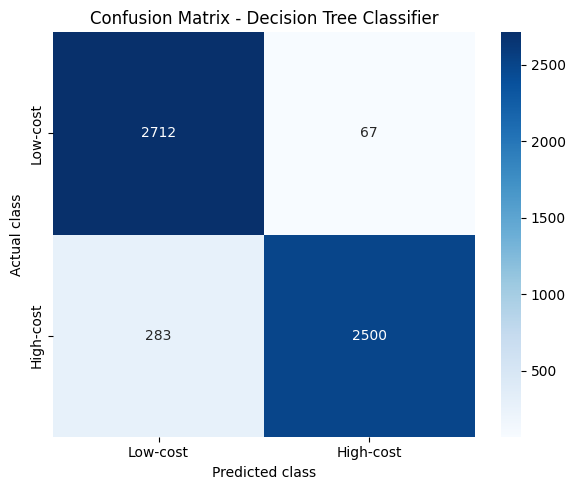

In [ ]:
prediction_map = {
    "Logistic Regression": logistic_predictions,
    "KNN Classifier": knn_predictions,
    "Decision Tree Classifier": tree_predictions,
    "Linear SVM": svm_predictions
}
best_predictions = prediction_map[best_algorithm_name]

print(classification_report(y_test, best_predictions, labels=["Low-cost", "High-cost"], zero_division=0))
cm = confusion_matrix(y_test, best_predictions, labels=["Low-cost", "High-cost"])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Low-cost", "High-cost"], yticklabels=["Low-cost", "High-cost"])
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title(f"Confusion Matrix - {best_algorithm_name}")
plt.tight_layout()
plt.show()

## 6. Final model and sample prediction

After evaluating all algorithms on the selected hold-out test set, fit the chosen algorithm on all available labeled rows for later use. The reported evaluation metrics remain the held-out test metrics from Section 4. The manual preprocessing steps are repeated for the full dataset; no pipeline is used.

In [ ]:
# Prepare the complete dataset manually for final model training.
X_full = X.copy()
for col in X_full.select_dtypes(include=np.number).columns:
    X_full[col] = X_full[col].fillna(X_full[col].median())
for col in X_full.select_dtypes(exclude=np.number).columns:
    modes = X_full[col].mode(dropna=True)
    fill_value = modes.iloc[0] if len(modes) else "Unknown"
    X_full[col] = X_full[col].fillna(fill_value)
X_full_encoded = pd.get_dummies(X_full, drop_first=False, dtype=int)

final_scaler = None
if best_algorithm_name in ["Logistic Regression", "KNN Classifier", "Linear SVM"]:
    final_scaler = StandardScaler()
    X_full_model = pd.DataFrame(final_scaler.fit_transform(X_full_encoded), columns=X_full_encoded.columns)
else:
    X_full_model = X_full_encoded

if best_algorithm_name == "Logistic Regression":
    final_model = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
elif best_algorithm_name == "KNN Classifier":
    final_model = KNeighborsClassifier(n_neighbors=5)
elif best_algorithm_name == "Decision Tree Classifier":
    final_model = DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE)
else:
    final_model = LinearSVC(random_state=RANDOM_STATE, max_iter=10000)

final_model.fit(X_full_model, y)
print(f"Final model trained on all {len(X_full_model):,} rows.")
print("Selected algorithm:", best_algorithm_name)

Final model trained on all 13,904 rows.
Selected algorithm: Decision Tree Classifier


In [ ]:
# Show the held-out test metrics for the selected algorithm.
best_row = algorithm_results.loc[algorithm_results["Algorithm"] == best_algorithm_name].iloc[0]
print("Final algorithm:", best_algorithm_name)
print("Evaluation split:", selected_split)
print(f"Accuracy : {best_row['Accuracy']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall   : {best_row['Recall']:.4f}")
print(f"F1-score : {best_row['F1-score']:.4f}")

Final algorithm: Decision Tree Classifier
Evaluation split: 60:40
Accuracy : 0.9371
Precision: 0.9739
Recall   : 0.8983
F1-score : 0.9346


In [ ]:
# Demonstrate a prediction on one held-out test row using the selected model from Section 4.
# This keeps the sample prediction consistent with the reported hold-out evaluation.
if best_algorithm_name == "Logistic Regression":
    sample_prediction = logistic_model.predict(X_test_scaled.iloc[[0]])[0]
elif best_algorithm_name == "KNN Classifier":
    sample_prediction = knn_model.predict(X_test_scaled.iloc[[0]])[0]
elif best_algorithm_name == "Decision Tree Classifier":
    sample_prediction = tree_model.predict(X_test_unscaled.iloc[[0]])[0]
else:
    sample_prediction = svm_model.predict(X_test_scaled.iloc[[0]])[0]

print("Actual class:", y_test.iloc[0])
print("Predicted class:", sample_prediction)

Actual class: Low-cost
Predicted class: Low-cost


## Conclusion

- The continuous claim amount was converted into a binary class using the dataset median.
- A single train-test split was selected using Logistic Regression and then kept fixed for the four-algorithm comparison.
- Logistic Regression, KNN, Decision Tree, and Linear SVM were implemented with separate model objects and explicit `.fit()` / `.predict()` calls.
- Preprocessing is performed manually; **the notebook does not use `Pipeline`**.
- The highest-F1 model is selected, while accuracy, precision, recall, and the confusion matrix provide additional evaluation context.

**Limitation:** `Low-cost` and `High-cost` are relative to this dataset's median threshold, not externally defined insurance pricing categories.